# 第18讲 main

按原单元编号阅读。配套讲解见本讲的解释.md，运行方法与记录见复现目录。


### 单元 0（code）：导入框架

torch提供实/复数Tensor与运算；nn为神经网络模块；np是NumPy别名。导入不加载模型。


In [4]:
# 导入PyTorch，使用实数、复数张量和自动求导。
import torch
# 导入Module基类，供位置表类继承。
from torch import nn
# NumPy别名np用于复数指数与几何绘图。
import numpy as np

### 单元 1（markdown）：复平面章节

相邻两个实通道可视作一个复数，尚未加入位置。


## complex plane

### 单元 2（markdown）：Euler公式与指数

i²=-1，exp(iθ)=cosθ+i sinθ。a+ib的指数半径exp(a)、角度b；Python用1j。exp(iπ)+1约0受浮点误差影响，不是额外模型步骤。

$$
\begin{split}
e^{i\pi}+1&=0\\
e^{i\pi}+1&=\left(\cos\pi + i\sin\pi\right) + 1 = -1 + 1=0
\end{split}
$$

- $x=a+ib$
    - $e^{x}=e^{a+ib}=e^ae^{ib}=e^a\left(\cos b+i\sin b\right)$


$$
\begin{split}
e^{i\pi}+1&=0\\
e^{i\pi}+1&=\left(\cos\pi + i\sin\pi\right) + 1 = -1 + 1=0
\end{split}
$$

- $x=a+ib$ 
    - $e^{x}=e^{a+ib}=e^ae^{ib}=e^a\left(\cos b+i\sin b\right)$

### 单元 3（markdown）：单位圆章节

半径为1的旋转因子与被旋转向量的长度不同。


### unit circle

### 单元 4（markdown）：单位模长

exp(iθ)的实部/虚部平方和为1；乘它只旋转二维向量，不改变长度。

- $e^{i\theta}$ 就是一个单位圆


- $e^{i\theta}$ 就是一个单位圆

### 单元 5（code）：画单位圆

linspace含两端，500个float64角度；np.exp(1j*thetas)为complex128[500]，real/imag为float64[500]。plot修改当前图，axis equal令坐标单位等长。不是loss或模型评测曲线。


(-1.0999791907454364,
 1.099999009083116,
 -1.0999945499436368,
 1.0999945499436368)

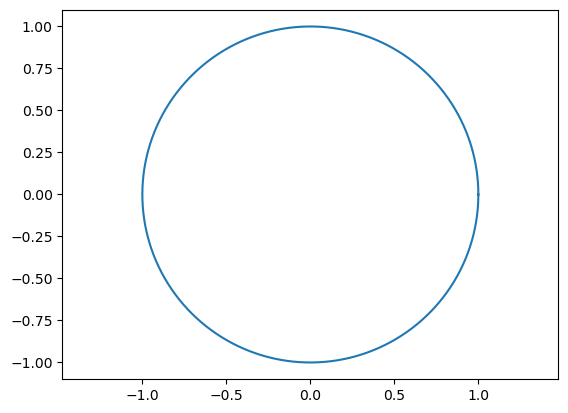

In [1]:
# NumPy别名np用于复数指数与几何绘图。
import numpy as np
# 绘图接口别名plt；验证选择Agg后端。
import matplotlib.pyplot as plt

# 500个float64弧度，包含0与2π；一个完整单位圆。
thetas = np.linspace(0, 2*np.pi, 500)

# 复数指数complex128[500]取实部cos→float64[500]。
xs = np.real(np.exp(1j*thetas))
# 取虚部sin→float64[500]；Python虚数单位是1j。
ys = np.imag(np.exp(1j*thetas))

# 连线绘单位圆，不是loss或模型性能曲线。
plt.plot(xs, ys)
# 两坐标轴单位等长，避免圆被显示成椭圆。
plt.axis('equal')

### 单元 6（markdown）：传统位置表章节

下面先生成sin/cos特征表，既没有加到embedding，也没有旋转Q/K。


## sin position encoding

### 单元 7（markdown）：奇偶位置公式

频率base^(-2j/d)，相邻通道sin/cos使用同一频率。位置t、通道对j与维度d区别明确；d要为正偶数。

$$
\begin{split}
PE(t,2i)&=\sin\left(\frac{t}{10000^{\frac{2i}{d_{model}}}}\right)\\
PE(t,2i+1)&=\cos\left(\frac{t}{10000^{\frac{2i}{d_{model}}}}\right)\\
\Downarrow\\
PE(t,i)&=\sin\left(\frac{t}{10000^{\frac{i}{d_{model}}}}\right), \quad \text{i is even}\\
PE(t,i)&=\cos\left(\frac{t}{10000^{\frac{i-1}{d_{model}}}}\right), \quad \text{i is odd}\\
\end{split}
$$


$$
\begin{split}
PE(t,2i)&=\sin\left(\frac{t}{10000^{\frac{2i}{d_{model}}}}\right)\\
PE(t,2i+1)&=\cos\left(\frac{t}{10000^{\frac{2i}{d_{model}}}}\right)\\
\Downarrow\\
PE(t,i)&=\sin\left(\frac{t}{10000^{\frac{i}{d_{model}}}}\right), \quad \text{i is even}\\
PE(t,i)&=\cos\left(\frac{t}{10000^{\frac{i-1}{d_{model}}}}\right), \quad \text{i is odd}\\
\end{split}
$$

### 单元 8（code）：配置小表

max_sequence_length=10为位置数量，d_model=6为教学表宽度；实际Llama precompute的dim是head_dim。


In [2]:
# 位置数量10，对应0..9，端点不包含10。
max_sequence_length = 10
# 教学通道数6；真实模型频率dim应使用head_dim。
d_model = 6

### 单元 9（code）：生成通道索引

arange右端不含，even_i=[0,2,4]、odd_i=[1,3,5]，float32[3]；dtype检查被注释，没有执行。print显示索引。


In [5]:
# 偶数通道0/2/4，float32[3]；右端不含。
even_i = torch.arange(0, d_model, 2).float()
# even_i.dtype
# 展示偶数通道索引，不修改数值。
print(even_i)
# 奇数通道1/3/5，float32[3]。
odd_i = torch.arange(1, d_model, 2).float()
# 展示奇数通道索引。
print(odd_i)

tensor([0., 2., 4.])
tensor([1., 3., 5.])


### 单元 10（code）：位置向量

position为float32[10]，值0到9，不含10；裸表达式只在Notebook自动展示。


In [7]:
# 一维位置float32[10]；供outer使用。
position = torch.arange(max_sequence_length, dtype=torch.float32)
# Notebook展示当前位置tensor；普通Python不自动显示。
position

tensor([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.])

### 单元 11（code）：sin表

1/pow(10000,even_i/d_model)是[3]频率；outer([10],[3])→[10,3]角度，再sin得到偶数通道。outer不对通道求和。


In [8]:
# [10]外积[3]频率→[10,3]角度再sin，指数除d_model。
even_pe = torch.sin(torch.outer(position, 1./torch.pow(10000, even_i/d_model)))
# 展示sin表，不更新对象。
even_pe

tensor([[ 0.0000,  0.0000,  0.0000],
        [ 0.8415,  0.0464,  0.0022],
        [ 0.9093,  0.0927,  0.0043],
        [ 0.1411,  0.1388,  0.0065],
        [-0.7568,  0.1846,  0.0086],
        [-0.9589,  0.2300,  0.0108],
        [-0.2794,  0.2749,  0.0129],
        [ 0.6570,  0.3192,  0.0151],
        [ 0.9894,  0.3629,  0.0172],
        [ 0.4121,  0.4057,  0.0194]])

### 单元 12（code）：cos表

odd_i-1=[0,2,4]使频率与sin一致，得到cos float32[10,3]；不能直接用奇数频率。


In [9]:
# odd_i-1使sin/cos频率配对；输出[10,3]。
odd_pe = torch.cos(torch.outer(position, 1./torch.pow(10000, (odd_i-1)/d_model)))
# 展示cos表，不更新对象。
odd_pe

tensor([[ 1.0000,  1.0000,  1.0000],
        [ 0.5403,  0.9989,  1.0000],
        [-0.4161,  0.9957,  1.0000],
        [-0.9900,  0.9903,  1.0000],
        [-0.6536,  0.9828,  1.0000],
        [ 0.2837,  0.9732,  0.9999],
        [ 0.9602,  0.9615,  0.9999],
        [ 0.7539,  0.9477,  0.9999],
        [-0.1455,  0.9318,  0.9999],
        [-0.9111,  0.9140,  0.9998]])

### 单元 13（code）：交错排列位置表

stack dim2→[10,3,2]，末轴顺序[sin,cos]；flatten轴1到2→[10,6]，保持位置轴，不做归约。


In [10]:
# 新轴2堆叠→[10,3,2]，末轴[sin,cos]。
stacked = torch.stack([even_pe, odd_pe], dim=2)
# 合并频率轴和二分量轴→[10,6]，保留位置轴。
pe = torch.flatten(stacked, start_dim=1, end_dim=2)
# 显示传统位置表，不是已经旋转的Q/K。
pe

tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0464,  0.9989,  0.0022,  1.0000],
        [ 0.9093, -0.4161,  0.0927,  0.9957,  0.0043,  1.0000],
        [ 0.1411, -0.9900,  0.1388,  0.9903,  0.0065,  1.0000],
        [-0.7568, -0.6536,  0.1846,  0.9828,  0.0086,  1.0000],
        [-0.9589,  0.2837,  0.2300,  0.9732,  0.0108,  0.9999],
        [-0.2794,  0.9602,  0.2749,  0.9615,  0.0129,  0.9999],
        [ 0.6570,  0.7539,  0.3192,  0.9477,  0.0151,  0.9999],
        [ 0.9894, -0.1455,  0.3629,  0.9318,  0.0172,  0.9999],
        [ 0.4121, -0.9111,  0.4057,  0.9140,  0.0194,  0.9998]])

### 单元 14（code）：实数位置表模块

class继承nn.Module；__init__、self、super初始化实例和基类。配置为普通字段，无Parameter。forward不接受x，每次重新构造[10,6]，不是缓存buffer，默认CPU；d为奇数时两支列数不同而stack报错。


In [11]:
# 定义位置表模块；同名重定义只改变名称指向，不改变旧对象。
class SinPositionEncoding(nn.Module):
    # 构造配置：位置数、偶数通道数、默认频率基数10000；没有Parameter。
    def __init__(self, max_sequence_length, d_model, base=10000):
        # 初始化Module基类；self表示当前实例。
        super().__init__()
        # 保存位置数量，forward每次重新生成表。
        self.max_sequence_length = max_sequence_length
        # 保存实例的通道配置；与全局d_model是不同变量。
        self.d_model = d_model
        # 保存频率基数，既非逐位置角度也非训练参数。
        self.base = base
    # 无输入张量，返回位置表；不缓存buffer或更新参数。
    def forward(self):
        # 按实例宽度生成偶数通道索引；奇数宽度会多一个通道对。
        even_i = torch.arange(0, self.d_model, 2).float()
        # 按实例宽度生成奇数索引；奇数宽度与even列数不等。
        odd_i = torch.arange(1, self.d_model, 2).float()
        # float32一维位置[T]，当前默认CPU。
        position = torch.arange(self.max_sequence_length, dtype=torch.float)
        # 按实例通道宽度计算频率，outer→[T,d/2]再sin。
        even_pe = torch.sin(torch.outer(position, 1./torch.pow(self.base, even_i/self.d_model)))
        # 配对频率计算cos表，与sin共享各对的频率。
        odd_pe = torch.cos(torch.outer(position,  1./torch.pow(self.base, (odd_i-1)/self.d_model)))
        # 新轴2堆叠→[10,3,2]，末轴[sin,cos]。
        stacked = torch.stack([even_pe, odd_pe], dim=2)
        # 输出传统交错表[T,d]；奇数维在stack处已失败。
        return torch.flatten(stacked, start_dim=1, end_dim=2)

### 单元 15（code）：调用实数类

spe是对象，spe()调用forward，返回[10,6]；创建对象不等于已经计算表。保存此类引用可与后面同名新类比较。


In [12]:
# 创建实例，不自动forward；后面同名类重新创建新对象。
spe = SinPositionEncoding(max_sequence_length=10, d_model=6)
# 通过Module调用forward，返回传统位置表[10,6]。
spe()

tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0464,  0.9989,  0.0022,  1.0000],
        [ 0.9093, -0.4161,  0.0927,  0.9957,  0.0043,  1.0000],
        [ 0.1411, -0.9900,  0.1388,  0.9903,  0.0065,  1.0000],
        [-0.7568, -0.6536,  0.1846,  0.9828,  0.0086,  1.0000],
        [-0.9589,  0.2837,  0.2300,  0.9732,  0.0108,  0.9999],
        [-0.2794,  0.9602,  0.2749,  0.9615,  0.0129,  0.9999],
        [ 0.6570,  0.7539,  0.3192,  0.9477,  0.0151,  0.9999],
        [ 0.9894, -0.1455,  0.3629,  0.9318,  0.0172,  0.9999],
        [ 0.4121, -0.9111,  0.4057,  0.9140,  0.0194,  0.9998]])

### 单元 16（markdown）：复数位置表章节

用于重建传统表的复数表示和真正RoPE旋转仍需区分。


## complex sin position encoding

### 单元 17（markdown）：Llama来源小节

下面函数来自Llama，精确提交见来源清单。


### llama2 

### 单元 18（markdown）：官方源码入口

原main链接会变化；本篇固定Meta提交7565eb6fee2175b2d4fe2cfb45067a61b35d7f5e。

- https://github.com/facebookresearch/llama/blob/main/llama/model.py


- https://github.com/facebookresearch/llama/blob/main/llama/model.py

### 单元 19（code）：预计算单位复数

普通函数，无self；dim偶数通道、end位置数量、theta默认10000为base。arange步长2、截取dim//2、float()/dim、幂倒数→频率[dim/2]；t[end]和outer→相位[end,dim/2]；ones_like半径1、polar→complex64同shape。freqs变量由频率变相位，两次print仅显示shape。无可学习参数或状态更新。


In [13]:
# 普通函数：dim为偶数通道，end位置数量，theta频率base默认10000；不旋转Q/K。
def precompute_freqs_cis(dim: int, end: int, theta: float = 10000.0):
    # 偶数索引除dim作指数→幂倒数频率[dim/2]；//整数除法，不能漏/div dim。
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    # int64[end]位置，0..end-1；与频率同设备，type ignore不影响运行。
    t = torch.arange(end, device=freqs.device)  # type: ignore
    # 外积把频率变为相位[end,dim/2]，变量freqs被复用。
    freqs = torch.outer(t, freqs).float()  # type: ignore
    # 展示实数相位shape，不表示复数dtype。
    print(freqs.shape)
    # 半径1、角度相位→complex64[end,dim/2]，实部cos/虚部sin。
    freqs_cis = torch.polar(torch.ones_like(freqs), freqs)  # complex64
    # shape同相位表，但dtype为complex64。
    print(freqs_cis.shape)
    # 返回旋转因子，未应用到任何Q/K。
    return freqs_cis

### 单元 20（markdown）：调用参数说明纠正

独立表例dim=d_model=6；真实模型dim=head_dim=D/H，不是整个模型宽度。end不包含端点，官方调用预留max_seq_len*2；theta是基数，不是直接角度。

- dim：d_model
- end: max_sequece_len,
- theta: base


- dim：d_model
- end: max_sequece_len,
- theta: base

### 单元 21（code）：生成复数表

dim6/end10→complex64[10,3]，0位置全1+0j；两次shape打印后返回表，不旋转任何Q/K。


In [14]:
# 生成complex64[10,3]，第0行全1+0j。
precompute_freqs_cis(6, 10)

torch.Size([10, 3])
torch.Size([10, 3])


tensor([[ 1.0000+0.0000j,  1.0000+0.0000j,  1.0000+0.0000j],
        [ 0.5403+0.8415j,  0.9989+0.0464j,  1.0000+0.0022j],
        [-0.4161+0.9093j,  0.9957+0.0927j,  1.0000+0.0043j],
        [-0.9900+0.1411j,  0.9903+0.1388j,  1.0000+0.0065j],
        [-0.6536-0.7568j,  0.9828+0.1846j,  1.0000+0.0086j],
        [ 0.2837-0.9589j,  0.9732+0.2300j,  0.9999+0.0108j],
        [ 0.9602-0.2794j,  0.9615+0.2749j,  0.9999+0.0129j],
        [ 0.7539+0.6570j,  0.9477+0.3192j,  0.9999+0.0151j],
        [-0.1455+0.9894j,  0.9318+0.3629j,  0.9999+0.0172j],
        [-0.9111+0.4121j,  0.9140+0.4057j,  0.9998+0.0194j]])

### 单元 22（code）：复数恢复传统表

view_as_real→float32[10,3,2]末轴[cos,sin]；flip轴2变[sin,cos]，flatten→[10,6]。单元素tuple(2,)尾逗号不能丢。flip适用于恢复传统表，不应额外用于实际Q/K旋转。


In [ ]:
# [10,3]→[10,3,2]实虚→flip成sin/cos→[10,6]；恢复传统表才flip。
torch.flip(torch.view_as_real(precompute_freqs_cis(6, 10)), dims=(2, )).flatten(start_dim=1, end_dim=2)

### 单元 23（markdown）：cis命名

cis意为cosine+i sine，描述单位复数因子。


### cis

### 单元 24（markdown）：实虚部排列

exp(ix)实部cos、虚部sin；传统表顺序sin/cos相反，故重建时flip。complex64的实部和虚部各占一个float32，因此它与对应的实数双通道表示占用相同字节数。

$$
e^{ix} = \cos x + i\sin x
$$

- https://en.wikipedia.org/wiki/Cis_(mathematics)
- 相邻的两个feature（一个偶数位，一个奇数位）
    - sin 视为复数的虚部，cos 视为复数的实部


$$
e^{ix} = \cos x + i\sin x
$$

- https://en.wikipedia.org/wiki/Cis_(mathematics)
- 相邻的两个feature（一个偶数位，一个奇数位）
    - sin 视为复数的虚部，cos 视为复数的实部

### 单元 25（markdown）：复数模块章节

下面同名类将遮盖原类名，但不会改变已经创建的旧spe实例。


### complex representation

### 单元 26（code）：同名类与全局变量缺陷

新forward只构造even_i和outer/polar，再view/flip/flatten。原分母写的是全局d_model，而非self.d_model！在当前全局6/实例6时正常；改实例宽度会依赖外部状态，无全局变量则NameError。注释版保留此语句，独立补充只修正这一Name再验证。奇数宽度5实际会输出6列而非报错，不能说正确支持奇数维。


In [15]:
# 定义位置表模块；同名重定义只改变名称指向，不改变旧对象。
class SinPositionEncoding(nn.Module):
    # 构造配置：位置数、偶数通道数、默认频率基数10000；没有Parameter。
    def __init__(self, max_sequence_length, d_model, base=10000):
        # 初始化Module基类；self表示当前实例。
        super().__init__()
        # 保存位置数量，forward每次重新生成表。
        self.max_sequence_length = max_sequence_length
        # 保存实例的通道配置；与全局d_model是不同变量。
        self.d_model = d_model
        # 保存频率基数，既非逐位置角度也非训练参数。
        self.base = base
    # 无输入张量，返回位置表；不缓存buffer或更新参数。
    def forward(self):
        # 按实例宽度生成偶数通道索引；奇数宽度会多一个通道对。
        even_i = torch.arange(0, self.d_model, 2).float()
        # float32一维位置[T]，当前默认CPU。
        position = torch.arange(self.max_sequence_length, dtype=torch.float)
        # 原缺陷：分母是外部全局d_model，非self.d_model！当前都为6掩盖问题，原语句保留。
        freqs = torch.outer(position, 1./torch.pow(self.base, even_i/d_model))
        # 半径1、角度相位→complex64[end,dim/2]，实部cos/虚部sin。
        freqs_cis = torch.polar(torch.ones_like(freqs), freqs)
        # 按sin/cos恢复传统表；odd d会输出d+1列，非正确奇数维支持。
        return torch.flip(torch.view_as_real(freqs_cis), dims=(2, )).flatten(start_dim=1, end_dim=2)

### 单元 27（code）：调用新类

重新创建spe后调用新forward；输出[10,6]仅在当前全局d_model=6满足预期。与实数类按float32容差比较，不能强求bit相等。


In [16]:
# 创建实例，不自动forward；后面同名类重新创建新对象。
spe = SinPositionEncoding(max_sequence_length=10, d_model=6)
# 通过Module调用forward，返回传统位置表[10,6]。
spe()

tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0464,  0.9989,  0.0022,  1.0000],
        [ 0.9093, -0.4161,  0.0927,  0.9957,  0.0043,  1.0000],
        [ 0.1411, -0.9900,  0.1388,  0.9903,  0.0065,  1.0000],
        [-0.7568, -0.6536,  0.1846,  0.9828,  0.0086,  1.0000],
        [-0.9589,  0.2837,  0.2300,  0.9732,  0.0108,  0.9999],
        [-0.2794,  0.9602,  0.2749,  0.9615,  0.0129,  0.9999],
        [ 0.6570,  0.7539,  0.3192,  0.9477,  0.0151,  0.9999],
        [ 0.9894, -0.1455,  0.3629,  0.9318,  0.0172,  0.9999],
        [ 0.4121, -0.9111,  0.4057,  0.9140,  0.0194,  0.9998]])

### 单元 28（code）：空代码格

原空格保留，仅加说明，不补造算法。


In [ ]:
# 原空代码格保留，不添加计算。
